In [ ]:
######################################################

#  Student Name: Valana Jones

#  Course Code: CSCI 460 -- Fall 2026

#  Assignment Due Date: Oct. 25th, 2026

#  GitHub Link: <https://github.com/ValanaJones/CSCI460F2026_Programing_Assignemnt1>

######################################################

In [18]:
# connect to google colab files
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Prepare data

In [ ]:
from sklearn.metrics import (
accuracy_score,
confusion_matrix,
ConfusionMatrixDisplay,
f1_score,
classification_report,
)
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
import warnings
from datetime import datetime
import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [43]:
#grab data
preamble='/content/drive/MyDrive/CSCI460/Naive_Bayes/'
df = pd.read_csv(preamble +'bank-full.csv', sep=";")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [44]:
#Check for any rows that have missing (NA) values from df
print(df[(df == '(NA)').any(axis=1)])
print(df[(df == 'NA').any(axis=1)])
print(df.isnull().sum())

# Note: There doesn't seem to be any missing values

Empty DataFrame
Columns: [age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome, y]
Index: []
Empty DataFrame
Columns: [age, job, marital, education, default, balance, housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome, y]
Index: []
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [45]:
#Map each categorical variables into an integer number starting at 0
vars = ['job', 'marital', 'education', 'contact',  'poutcome']
bvars = ['default', 'housing', 'loan','y']
bin = {'yes':1,'no':0}
months = {'jan':0,'feb':1,'mar':2,'apr':3,'may':4,'jun':5,'jul':6,'aug':7,'sep':8,'oct':9,'nov':10,'dec':11}

for var in vars :
  print(df[var].unique())
  df[var] = df[var].astype("category").cat.codes

for bvar in bvars :
  print(df[bvar].unique())
  df[bvar] = df[bvar].map(bin)

print(df['month'].unique())
df['month'] = df['month'].map(months)

df.head()

['management' 'technician' 'entrepreneur' 'blue-collar' 'unknown'
 'retired' 'admin.' 'services' 'self-employed' 'unemployed' 'housemaid'
 'student']
['married' 'single' 'divorced']
['tertiary' 'secondary' 'unknown' 'primary']
['unknown' 'cellular' 'telephone']
['unknown' 'failure' 'other' 'success']
['no' 'yes']
['yes' 'no']
['no' 'yes']
['no' 'yes']
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,4,261,1,-1,0,3,0
1,44,9,2,1,0,29,1,0,2,5,4,151,1,-1,0,3,0
2,33,2,1,1,0,2,1,1,2,5,4,76,1,-1,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,4,92,1,-1,0,3,0
4,33,11,2,3,0,1,0,0,2,5,4,198,1,-1,0,3,0


In [46]:
#Set X and Y
X = df.drop(columns=['y'])
Y = df['y']

# Training and Testing

In [ ]:
avg_acc_arr = []
avg_f1_arr = []
std_acc_arr = []
std_f1_arr = []

with open(preamble + datetime.today().strftime('%Y-%m-%d-%H:%M:%S') + 'output.txt', 'w') as file:
  for tsize in range(1,10):
    file.write("iteration " + str(tsize) + ": use " + str(tsize*10) + "% for training and " + str((10 - tsize)*10) + "% for testing\n")
    accuracy_arr = []
    f1_arr = []

    for trial in range(1, 11):
      file.write("Trial " + str(trial) + ":\n")
      #Split X and Y using stratified random sampling
      X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=tsize/10, stratify=Y)

      #Build a Gaussian classifier
      clf = GaussianNB()

      #Fit the model to the training data
      clf.fit(X_train, Y_train)

      #Obtain model predictions on test data
      Y_pred_list = []

      for index, item in X_test.iterrows() :
        arr_item = [np.array(item)]
        #Turning off warnings (temporarily) to simplify output
        with warnings.catch_warnings():
          warnings.simplefilter('ignore')
          guess = int(clf.predict(arr_item))
          Y_pred_list.append(guess)

      Y_pred = pd.DataFrame(Y_pred_list)
      Y_pred.index = Y_test.index

      # measure the performance
      accuracy = accuracy_score(Y_pred, Y_test)
      f1 = f1_score(Y_pred, Y_test, average="weighted")
      file.write("The accuracy of my Naive Bayes Model is: " + str(accuracy) + "\n")
      file.write("The F1 Score of my Naive Bayes Model is: " + str(f1) + "\n")
      accuracy_arr.append(accuracy)
      f1_arr.append(f1)

    avg_acc_arr.append(np.mean(np.array(accuracy_arr)))
    avg_f1_arr.append(np.mean(np.array(f1_arr)))
    std_acc_arr.append(np.std(np.array(accuracy_arr)))
    std_f1_arr.append(np.std(np.array(f1_arr)))


In [58]:
print(avg_acc_arr)
print(avg_f1_arr)
print(std_acc_arr)
print(std_f1_arr)

[np.float64(0.8362595232243795), np.float64(0.837559788769388), np.float64(0.8348932002022245), np.float64(0.8429350831275114), np.float64(0.8446872511722552), np.float64(0.8417085982858723), np.float64(0.8373488646416986), np.float64(0.8371779276788676), np.float64(0.8403582485625829)]
[np.float64(0.8260369624327966), np.float64(0.8279848251751716), np.float64(0.8245283665086912), np.float64(0.8358227681313719), np.float64(0.8376829561736185), np.float64(0.8335518428911994), np.float64(0.8284044910248918), np.float64(0.8280518095824452), np.float64(0.8318980493804414)]
[np.float64(0.00900564466103135), np.float64(0.00497527099306362), np.float64(0.009096787700939971), np.float64(0.005763994299741841), np.float64(0.005418292380690839), np.float64(0.00365546455806755), np.float64(0.003913351023932068), np.float64(0.003534568586657478), np.float64(0.004018992118317957)]
[np.float64(0.012283221151251284), np.float64(0.006612626189627248), np.float64(0.01203558091661637), np.float64(0.0070

9

# Reporting

In [65]:
training_portion = ['0.1','0.2','0.3','0.4','0.5','0.6','0.7','0.8','0.9']
xl= 'Portion of training data'

0.845


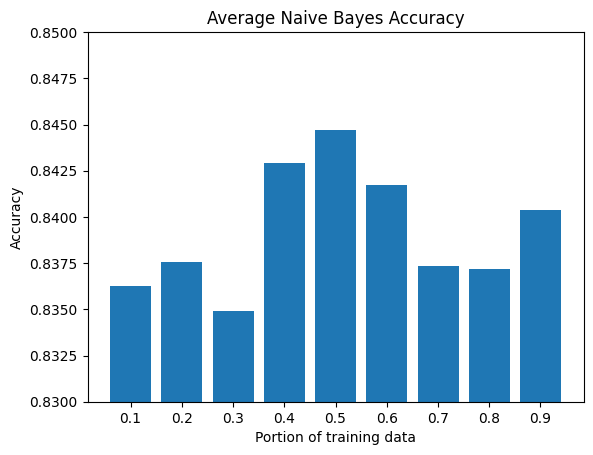

In [79]:
#Plot average Accuracy
plt.bar(training_portion,avg_acc_arr)
plt.ylim(round(min(avg_acc_arr),3) - 0.005, round(max(avg_acc_arr),3) + 0.005)
plt.title('Average Naive Bayes Accuracy')
plt.xlabel(xl)
plt.ylabel('Accuracy')
plt.show()

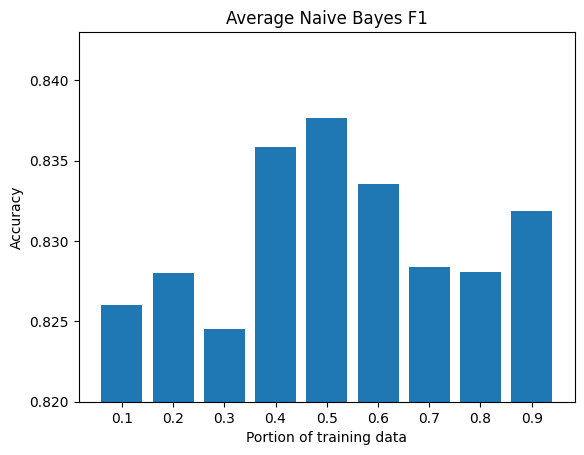

In [81]:
#Plot average F1
plt.bar(training_portion,avg_f1_arr)
plt.ylim(round(min(avg_f1_arr),3) - 0.005, round(max(avg_f1_arr),3) + 0.005)
plt.title('Average Naive Bayes F1')
plt.xlabel(xl)
plt.ylabel('Accuracy')
plt.show()

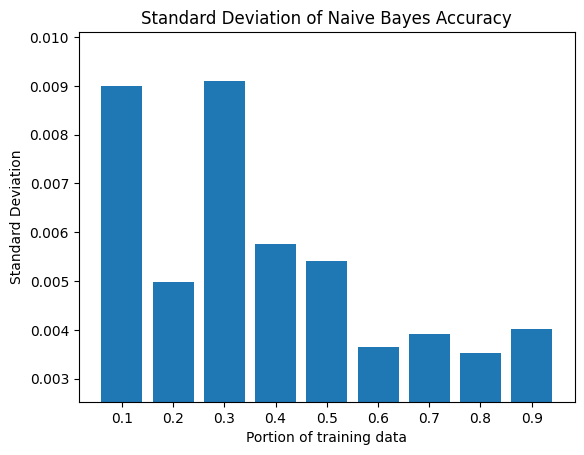

In [83]:
#Plot standard deviation of Accuracy
plt.bar(training_portion,std_acc_arr)
plt.ylim(round(min(std_acc_arr),5)-.001, round(max(std_acc_arr),5)+.001)
plt.title('Standard Deviation of Naive Bayes Accuracy')
plt.xlabel(xl)
plt.ylabel('Standard Deviation')
plt.show()

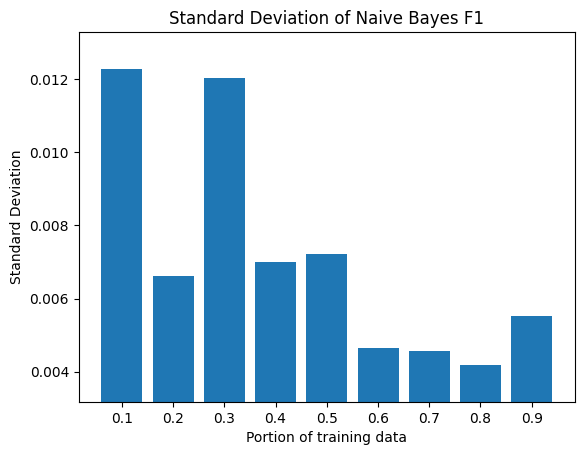

In [85]:
#Plot standard deviation of F1
plt.bar(training_portion,std_f1_arr)
plt.ylim(round(min(std_f1_arr),5)-.001, round(max(std_f1_arr),5)+.001)
plt.title('Standard Deviation of Naive Bayes F1')
plt.xlabel(xl)
plt.ylabel('Standard Deviation')
plt.show()

In [ ]:
#Table of results
fig = go.Figure(data=[go.Table(header=dict(values=['Training Data', 'Average Naive Bayes Accuracy','Average Naive Bayes F1','Standard Deviation of Naive Bayes Accuracy','Standard Deviation of Naive Bayes F1']),
                 cells=dict(values=[['0.1','0.2','0.3','0.4','0.5','0.6','0.7','0.8','0.9'],avg_acc_arr, avg_f1_arr, std_acc_arr, std_f1_arr]))
                     ])
fig.show()